# PCS113 - Linear Algebra and Statistical Methods
## Lab Assignment (Labs 1-10)

**Name:** Ishpuneet Singh &emsp; **Roll No.:** 8026320041

**Submitted to:** Dr. Karamjeet Singh

In [ ]:
# imports for the whole nb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from PIL import Image
from IPython.display import display
from sklearn.datasets import load_iris, load_sample_image

rng = np.random.default_rng(42) # fixed seed so we get the same random numbers every run
np.set_printoptions(precision=4, suppress=True) # 4 decimals, no 1e-05 type printing
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# helpers are written from the math formula (raw code) and then checked with the inbuilt
# numpy / scipy fxn. each helper is written once and reused later:
# lab 1 - load_gray_image, dot_product, l2_norm, cosine, is_orthogonal
# lab 2 - compute_rank, check_linear_independence, gram_schmidt
# lab 3 - solve_gauss
# lab 4 - covariance_matrix, standardize, pca
# lab 5 - dependent_columns, check_csv_independence
# lab 6 - box_muller, normal_pdf, empirical_pmf, expectation
# lab 7 - mean_std, percent_within, z_scores
# lab 8 - sample_means
# lab 9 - chi_square_gof, t_test_pooled, f_test
# lab 10 - confusion_counts, error_report
# no uploads needed, the nb makes its own csv files and 32x32 img

# Lab 1 - data frame from real data, l2 norm, inner product, orthogonality

Q1 (a) make a DF or 2D array by reading an img or csv / xls file that has real data

Q1 (b) fetch any 2 cols or rows and find the l2 norm, orthogonality and inner product

In [2]:
# Q1 (a) reading from CSV
# iris dataset = real flower measurements in cm (fisher, 1936), it comes with sklearn
# save it as a csv first and then read it back like any downloaded csv
iris = load_iris(as_frame=True).frame
# short col names
iris.columns = ["sepal_len", "sepal_wid", "petal_len", "petal_wid", "species"]
iris.to_csv("iris.csv", index=False)

df = pd.read_csv("iris.csv")
print("shape of DF:", df.shape) # 150 rows, 5 cols
df.head()

shape of DF: (150, 5)


,sepal_len,sepal_wid,petal_len,petal_wid,species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


img as a 2D array, shape: (32, 32) | pixels from 4.0 to 253.0


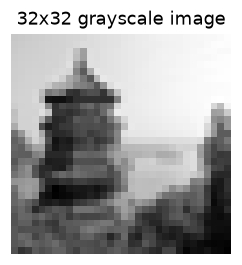

In [3]:
# Q1 (a) reading an img -> 2D array
# helper - load_gray_image
# why - lab 1, 2(c) and 6(c) all need an img as a matrix, so do it once here
# 1. convert to grayscale ("L") so every pixel is 1 number -> img becomes a 2D matrix
# 2. resize to 32x32 bc the questions ask for that size
# 3. convert to float - pixels are uint8 (0-255) and uint8 maths wraps around silently
#    eg np.dot of [200, 200] with itself in uint8 = 128 not 80000
#    so every dot product would be wrong

IMAGE_PATH = None # your own img path here, None = sample photo that comes with sklearn

def load_gray_image(path=None, size=(32, 32)):
  if path is None:
    Image.fromarray(load_sample_image("china.jpg")).save("photo.png")
    path = "photo.png"
  img = Image.open(path).convert("L").resize(size) # "L" = 8 bit grayscale
  return np.array(img, dtype=float)

img = load_gray_image(IMAGE_PATH)
print("img as a 2D array, shape:", img.shape, "| pixels from", img.min(), "to", img.max())
plt.figure(figsize=(2.6, 2.6))
plt.imshow(img, cmap="gray"); plt.title("32x32 grayscale image")
plt.axis("off"); plt.show()

In [4]:
# Q1 (b)
# everything in (b) is built on the dot product, so write that once and reuse it

# helper - dot product (inner product)
# math - <u,v> = u1*v1 + u2*v2 ..... + un*vn
# for complex vectors its conj(u_i) * v_i (lab 2c says C^5x1)
# for real nums conj does nothing
def dot_product(arr1, arr2):
  arr1, arr2 = np.ravel(arr1), np.ravel(arr2) # works for row, col or 1d vectors
  if len(arr1) != len(arr2):
    raise ValueError("vectors must be the same length")
  total_sum = 0.0
  for i in range(len(arr1)):
    total_sum += np.conj(arr1[i]) * arr2[i] # sum of u[i]*v[i]
  return total_sum

# helper - l2 norm
# math - (x1^2 + x2^2 ..... + xn^2)^1/2 = sqrt(<v,v>)
def l2_norm(arr):
  return abs(dot_product(arr, arr)) ** 0.5 # raise to pwr 0.5, ie sqrt

# helper - cos of the angle b/w 2 vectors
# math - cos(theta) = <u,v> / (||u|| * ||v||)
# why - the angle doesnt depend on how big the numbers are
def cosine(arr1, arr2):
  return dot_product(arr1, arr2) / (l2_norm(arr1) * l2_norm(arr2))

# helper - orthogonality check
# vectors are orthogonal if they have dot product = 0 (angle = 90 deg)
# BUT decimals are stored approx, so a 0 dot product comes out like -3.55e-15
# (this happened in my earlier gram schmidt, it said "not orthogonal" for -3.55e-15)
# so instead of "== 0" check |cos(theta)| < a small tolerance
def is_orthogonal(arr1, arr2, tol=1e-9):
  if l2_norm(arr1) == 0 or l2_norm(arr2) == 0:
    return True # zero vector is orthogonal to everything
  return abs(cosine(arr1, arr2)) < tol

In [5]:
# fetch 2 cols, 2 rows, 2 img rows + a control pair that we know is orthogonal
X = df.drop(columns="species").to_numpy(dtype=float) # 150 x 4, species is just a label

pairs = {
  "cols sepal_len & petal_len": (X[:, 0], X[:, 2]),
  "rows 0 & 1 (two flowers)": (X[0], X[1]),
  "img rows 0 & 1": (img[0], img[1]),
  "control pair [1,2,3] & [2,-1,0]": (np.array([1, 2, 3]), np.array([2, -1, 0])),
}
for name, (u, v) in pairs.items():
  # clip bc rounding can give cos = 1.0000001 and arccos breaks
  angle = np.degrees(np.arccos(np.clip(cosine(u, v), -1, 1)))
  nu, nv, ip = l2_norm(u), l2_norm(v), dot_product(u, v)
  print(name)
  print(f"   ||u|| = {nu:9.3f}   ||v|| = {nv:9.3f}   <u,v> = {ip:11.3f}")
  print(f"   angle = {angle:6.2f} deg   orthogonal? {is_orthogonal(u, v)}")

# check with inbuilt numpy
u, v = X[:, 0], X[:, 2]
print("\ninbuilt numpy check: norm", np.isclose(l2_norm(u), np.linalg.norm(u)),
      "| inner product", np.isclose(dot_product(u, v), u @ v))

# result - none of the real data pairs are orthogonal, makes sense:
# all measurements / pixels are >= 0 so <u,v> is a sum of +ve terms, cant be 0
# control pair = 2 - 2 + 0 = 0 -> orthogonal, so the check works both ways

cols sepal_len & petal_len
   ||u|| =    72.276   ||v|| =    50.820   <u,v> =    3483.760
   angle =  18.48 deg   orthogonal? False
rows 0 & 1 (two flowers)
   ||u|| =     6.345   ||v|| =     5.917   <u,v> =      37.490
   angle =   3.05 deg   orthogonal? False
img rows 0 & 1
   ||u|| =  1281.576   ||v|| =  1284.923   <u,v> = 1646696.000
   angle =   0.35 deg   orthogonal? False
control pair [1,2,3] & [2,-1,0]
   ||u|| =     3.742   ||v|| =     2.236   <u,v> =       0.000
   angle =  90.00 deg   orthogonal? True

inbuilt numpy check: norm True | inner product True


# Lab 2 - student vectors, rank, inverse, linear independence, gram schmidt

each student = [Math, Physics, Programming, Attendance]: {[80, 75, 90, 95], [70, 65, 80, 90], [90, 85, 95, 98], [60, 55, 70, 80], [85, 80, 92, 96]}

Q2 (a) make vectors V1, V2, V3, V4, put them in a matrix and find its inverse and rank

Q2 (b) are the vectors {[1,2,3], [2,4,6], [1,0,1]} linearly independent or dependent?

Q2 (c) read a 32x32 img, flatten it, take two C 5x1 col vectors and make them orthogonal with gram schmidt

In [6]:
# helper - rank of a matrix (raw code)
# why - rank is needed in 2(a), 2(b), lab 3 (unique solution?) and lab 5 (csv cols
# independent?) so write it once
# math - row reduce to echelon form (gaussian elimination), rank = no. of pivots
# partial pivoting = use the biggest entry in the col as pivot, keeps rounding errors low
# tolerance = after elimination a "zero" is like 1e-15 not exactly 0, so tiny = 0
def compute_rank(A, rel_tol=1e-10):
  M = np.array(A, dtype=float) # float copy so we dont change A
  n_rows, n_cols = M.shape
  tol = rel_tol * max(1.0, np.abs(M).max())
  rank = 0
  for c in range(n_cols):
    if rank == n_rows:
      break
    p = rank + np.argmax(np.abs(M[rank:, c])) # row with the biggest entry in col c
    if abs(M[p, c]) < tol:
      continue # no pivot -> col c depends on the earlier cols
    M[[rank, p]] = M[[p, rank]] # swap pivot row up
    for r in range(rank + 1, n_rows):
      M[r] -= (M[r, c] / M[rank, c]) * M[rank] # make entries below the pivot 0
    rank += 1
  return rank

# helper - linear independence check
# k vectors are independent if rank of [v1 v2 ... vk] = k (none is a combo of the others)
def check_linear_independence(vectors):
  return compute_rank(np.column_stack(vectors)) == len(vectors)

In [7]:
# Q2 (a)
# V1..V4 = one vector per subject = a col of the table (5 students -> each one is 5x1)
students = np.array([[80, 75, 90, 95],
                     [70, 65, 80, 90],
                     [90, 85, 95, 98],
                     [60, 55, 70, 80],
                     [85, 80, 92, 96]], dtype=float)
subjects = ["Math", "Physics", "Programming", "Attendance"]

V1, V2, V3, V4 = (students[:, j] for j in range(4))
for k, (name, V) in enumerate(zip(subjects, (V1, V2, V3, V4)), start=1):
  print(f"V{k} ({name:11s}) = {V}")

A = np.column_stack([V1, V2, V3, V4]) # 5 x 4 matrix
print("\nA =\n", A, "\nshape:", A.shape)
print("rank(A): raw =", compute_rank(A), "| inbuilt numpy =", np.linalg.matrix_rank(A))

V1 (Math       ) = [80. 70. 90. 60. 85.]
V2 (Physics    ) = [75. 65. 85. 55. 80.]
V3 (Programming) = [90. 80. 95. 70. 92.]
V4 (Attendance ) = [95. 90. 98. 80. 96.]

A =
 [[80. 75. 90. 95.]
 [70. 65. 80. 90.]
 [90. 85. 95. 98.]
 [60. 55. 70. 80.]
 [85. 80. 92. 96.]] 
shape: (5, 4)
rank(A): raw = 4 | inbuilt numpy = 4


In [8]:
# inverse only exists for a square matrix with full rank, A is 5x4 -> no A^-1
# but rank(A) = 4 = no. of cols -> A^T A (4x4) is invertible
# so A has a left inverse = moore-penrose pseudo inverse
# math - A+ = (A^T A)^-1 A^T  and  A+ A = I4
A_plus = np.linalg.inv(A.T @ A) @ A.T
print("pseudo inverse A+ (4 x 5) =\n", A_plus)
print("A+ A = I4 ?", np.allclose(A_plus @ A, np.eye(4)),
      "| same as inbuilt np.linalg.pinv ?", np.allclose(A_plus, np.linalg.pinv(A)))

# if a square matrix is wanted -> first 4 students (4x4), this one has a normal inverse
S = students[:4]
print("\nsquare case S (first 4 students): det =", round(np.linalg.det(S), 2),
      "| rank =", compute_rank(S))
S_inv = np.linalg.inv(S)
print("S^-1 =\n", S_inv)
print("S S^-1 = I4 ?", np.allclose(S @ S_inv, np.eye(4)))

pseudo inverse A+ (4 x 5) =
 [[-0.5281 -2.0151  0.4531  2.0453  0.2448]
 [ 0.2435  2.0754 -0.2608 -2.0261 -0.2319]
 [ 0.4644 -0.3591 -0.226   0.0774  0.0434]
 [-0.1778  0.3988  0.037  -0.1963 -0.0616]]
A+ A = I4 ? True | same as inbuilt np.linalg.pinv ? True

square case S (first 4 students): det = -1250.0 | rank = 4
S^-1 =
 [[-0.44 -2.02  0.6   2.06]
 [ 0.16  2.08 -0.4  -2.04]
 [ 0.48 -0.36 -0.2   0.08]
 [-0.2   0.4   0.   -0.2 ]]
S S^-1 = I4 ? True


In [9]:
# Q2 (b)
vectors = [np.array([1, 2, 3]), np.array([2, 4, 6]), np.array([1, 0, 1])]
B = np.column_stack(vectors)
print("vectors as cols:\n", B)
print("rank =", compute_rank(B), "for", len(vectors), "vectors ->",
      "INDEPENDENT" if check_linear_independence(vectors) else "DEPENDENT")
print("det =", round(abs(np.linalg.det(B)), 10)) # abs() so it doesnt print -0.0
print("v2 == 2 * v1 ?", np.array_equal(vectors[1], 2 * vectors[0]))

# result - dependent, rank 2 < 3 and det = 0
# bc v2 = 2*v1 -> 2*v1 - v2 + 0*v3 = 0 is a non zero combo that gives 0
# only 2 of them (v1 and v3) are independent

vectors as cols:
 [[1 2 1]
 [2 4 0]
 [3 6 1]]
rank = 2 for 3 vectors -> DEPENDENT
det = 0.0
v2 == 2 * v1 ? True


In [10]:
# Q2 (c)
# helper - gram schmidt orthogonalisation
# why - turns independent vectors into orthogonal ones that span the same space
# math - u1 = v1
#        u2 = v2 - (<u1,v2> / <u1,u1>) * u1   ie remove the part of v2 along u1
#        uk = vk - sum of (<uj,vk> / <uj,uj>) * uj   for all j < k
# subtracting 1 projection at a time = same answer, but more stable with decimals
# if nothing is left after subtracting -> vectors were dependent -> error
# normalize=True also divides by the length -> orthonormal vectors
# (C^5x1 = complex, dot_product already uses conj, and pixels are real anyway)
def gram_schmidt(vectors, normalize=False):
  basis = []
  for v in vectors:
    u = np.array(v) * 1.0 # float copy of v
    for q in basis:
      u = u - (dot_product(q, u) / dot_product(q, q)) * q
    if l2_norm(u) < 1e-10 * l2_norm(v):
      raise ValueError("the vectors are linearly dependent")
    basis.append(u)
  if normalize:
    basis = [u / l2_norm(u) for u in basis]
  return basis

In [11]:
x = img.flatten() # 32 x 32 img -> 1 vector of 1024 pixels
print("flattened img: vector of length", x.size)

# 2 col vectors (5x1) from 2 different parts of the img
# (pixels next to each other are almost the same -> vectors would be almost parallel)
v1 = x[0:5].reshape(5, 1)
v2 = x[600:605].reshape(5, 1)
print("v1 =", v1.ravel(), "\nv2 =", v2.ravel())
angle = np.degrees(np.arccos(cosine(v1, v2)))
print(f"before: <v1,v2> = {dot_product(v1, v2):.2f}, angle = {angle:.2f} deg,",
      "orthogonal?", is_orthogonal(v1, v2))

u1, u2 = gram_schmidt([v1, v2])
print("\nu1 =", u1.ravel(), "\nu2 =", u2.ravel())
print(f"after : <u1,u2> = {dot_product(u1, u2):.2e}, orthogonal? {is_orthogonal(u1, u2)}")

e1, e2 = gram_schmidt([v1, v2], normalize=True) # orthonormal version
E = np.hstack([e1, e2]) # 5 x 2
print("\northonormal e1 =", e1.ravel(), "\n            e2 =", e2.ravel())
print("E^T E = I2 ?", np.allclose(E.T @ E, np.eye(2)))

# result - before: not orthogonal (all pixels are +ve)
# after gram schmidt <u1,u2> ~ 1e-12 = 0 up to rounding -> orthogonal
# E^T E = I -> e1, e2 are orthonormal

flattened img: vector of length 1024
v1 = [198. 200. 202. 204. 205.] 
v2 = [196. 216. 219. 172.  95.]
before: <v1,v2> = 180809.00, angle = 14.74 deg, orthogonal? False

u1 = [198. 200. 202. 204. 205.] 
u2 = [ 20.2064  38.4308  39.6551  -9.1206 -87.0085]
after : <u1,u2> = 7.28e-12, orthogonal? True

orthonormal e1 = [0.4388 0.4432 0.4476 0.4521 0.4543] 
            e2 = [ 0.1917  0.3646  0.3762 -0.0865 -0.8254]
E^T E = I2 ? True


# Lab 3 - marks of ram, sham, wilson as linear equations

Q3 translate the marks of Ram, Sham and Wilson in English, Punjabi and Maths into a set of linear equations and find the solution

In [12]:
# Q3
# idea - school makes a final score = wE*English + wP*Punjabi + wM*Maths, weights unknown
# we know the marks + final score of all 3 students -> 3 eqns, 3 unknowns -> A w = b
#
#   student   english  punjabi  maths   final
#   ram         78       85      92     86.4
#   sham        65       90      70     72.5
#   wilson      88       60      75     75.9

# helper - solve A x = b with gaussian elimination (raw code)
# 1. forward elimination (with partial pivoting) -> [A | b] becomes upper triangular
# 2. back substitution from the last eqn up: x_i = (b_i - sum of a_ij*x_j, j > i) / a_ii
#    that sum is just a dot product, so reuse dot_product from lab 1
def solve_gauss(A, b):
  M = np.column_stack([A, b]).astype(float) # augmented matrix [A | b]
  n = len(b)
  for c in range(n): # forward elimination
    p = c + np.argmax(np.abs(M[c:, c]))
    M[[c, p]] = M[[p, c]]
    for r in range(c + 1, n):
      M[r] -= (M[r, c] / M[c, c]) * M[c]
  x = np.zeros(n)
  for i in range(n - 1, -1, -1): # back substitution
    x[i] = (M[i, n] - dot_product(M[i, i + 1:n], x[i + 1:])) / M[i, i]
  return x, M

In [13]:
names = ["Ram", "Sham", "Wilson"]
marks = np.array([[78, 85, 92], # english, punjabi, maths
                  [65, 90, 70],
                  [88, 60, 75]], dtype=float)
final = np.array([86.4, 72.5, 75.9])

print("system of linear equations:")
for name, row, rhs in zip(names, marks, final):
  print(f"   {row[0]:.0f} wE + {row[1]:.0f} wP + {row[2]:.0f} wM = {rhs}    ({name})")

# before solving - if rank(A) = rank([A|b]) = 3 (= no. of unknowns) -> exactly 1 solution
r_A, r_Ab = compute_rank(marks), compute_rank(np.column_stack([marks, final]))
print(f"\nrank(A) = {r_A}, rank([A|b]) = {r_Ab} ->",
      "unique solution" if r_A == r_Ab == 3 else "no unique solution")

w, U = solve_gauss(marks, final)
print("\nupper triangular [U | c] after forward elimination:\n", U)
print("\nsolution: wE = %.3f, wP = %.3f, wM = %.3f   (sum = %.3f)" % (*w, w.sum()))
print("same as inbuilt np.linalg.solve ?", np.allclose(w, np.linalg.solve(marks, final)))
print("check A w =", marks @ w, "= b")

# result - wE = 0.3, wP = 0.2, wM = 0.5 -> 30% english, 20% punjabi, 50% maths
# weights add up to 1 so the final score is a weighted avg

system of linear equations:
   78 wE + 85 wP + 92 wM = 86.4    (Ram)
   65 wE + 90 wP + 70 wM = 72.5    (Sham)
   88 wE + 60 wP + 75 wM = 75.9    (Wilson)

rank(A) = 3, rank([A|b]) = 3 -> unique solution

upper triangular [U | c] after forward elimination:
 [[88.     60.     75.     75.9   ]
 [ 0.     45.6818 14.6023 16.4375]
 [ 0.      0.     15.352   7.676 ]]

solution: wE = 0.300, wP = 0.200, wM = 0.500   (sum = 1.000)
same as inbuilt np.linalg.solve ? True
check A w = [86.4 72.5 75.9] = b


# Lab 4 - salary and education csv, covariance, eigen values, PCA

Q4 make salary and education data in a csv file, read it, make the vectors, find the eigen values, covariance matrix and apply PCA to reduce the dimensions of the data

In [14]:
# Q4
# 15 employees - years of education + monthly salary (in thousand rs)
csv_text = '''Education_Years,Salary_kINR
10,18
12,22
12,26
13,27
14,30
14,34
15,35
16,38
16,44
17,46
18,52
18,48
19,58
20,62
21,70
'''
with open("salary_education.csv", "w") as f: # make the csv
  f.write(csv_text)

data = pd.read_csv("salary_education.csv") # read it back
education = data["Education_Years"].to_numpy(dtype=float) # vector 1
salary = data["Salary_kINR"].to_numpy(dtype=float) # vector 2
print("education vector:", education)
print("salary vector   :", salary)
X = np.column_stack([education, salary]) # 15 x 2 data matrix, 1 row per employee

education vector: [10. 12. 12. 13. 14. 14. 15. 16. 16. 17. 18. 18. 19. 20. 21.]
salary vector   : [18. 22. 26. 27. 30. 34. 35. 38. 44. 46. 52. 48. 58. 62. 70.]


In [15]:
# helper - covariance matrix (raw)
# math - centre every col (subtract its mean) -> C = Xc^T Xc / (n - 1)
# diagonal = variances, off diagonal = covariances
# each entry is a dot product of 2 centred cols (same idea as lab 1)
def covariance_matrix(X):
  Xc = X - X.mean(axis=0) # centre every col
  return Xc.T @ Xc / (len(X) - 1)

# helper - standardize, every col -> mean 0 and sd 1, ie z = (x - mean) / sd
# why - salary is in thousands of rs and education in years, without this the col with
# bigger numbers takes over PCA just bc of its unit (shown below)
def standardize(X):
  return (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)

# helper - PCA, all the steps in one place
# 1. standardize
# 2. covariance of the standardized data (= correlation matrix)
# 3. eigen values + vectors with np.linalg.eigh (made for symmetric matrices -> real
#    eigen values and orthonormal eigen vectors), sort biggest first
# 4. eigen value = variance along its eigen vector -> lambda_i / sum = % variance kept
# 5. project the data on the first k eigen vectors -> reduced data
def pca(X, k):
  Z = standardize(X) # step 1
  C = covariance_matrix(Z) # step 2
  eigvals, eigvecs = np.linalg.eigh(C) # step 3
  order = np.argsort(eigvals)[::-1] # biggest eigen value first
  eigvals, eigvecs = eigvals[order], eigvecs[:, order]
  return Z @ eigvecs[:, :k], eigvals, eigvecs # step 5

In [16]:
# covariance of the raw vectors
C_raw = covariance_matrix(X)
print("covariance matrix (raw units):\n", C_raw)
print("same as inbuilt np.cov ?", np.allclose(C_raw, np.cov(X, rowvar=False)))
ev, evec = np.linalg.eigh(C_raw)
print("raw eigen values:", ev[::-1], "| first eigen vector:", evec[:, -1])
print("   -> points almost along the salary axis, only bc salary has bigger numbers")

# PCA on standardized data: 2 dims -> 1 dim
scores, eigvals, eigvecs = pca(X, k=1)
C_std = covariance_matrix(standardize(X))
print("\ncovariance of standardized data (= correlation matrix):\n", C_std)
print("eigen values :", eigvals)
print("eigen vectors (cols):\n", eigvecs)
print("C v = lambda v for both ?", np.allclose(C_std @ eigvecs, eigvecs * eigvals))
tr, det = np.trace(C_std), np.linalg.det(C_std)
char_eq = eigvals ** 2 - tr * eigvals + det # 2x2 characteristic eqn
print("2x2 check, lambda^2 - trace*lambda + det = 0 ?", np.allclose(char_eq, 0))
print("variance explained by PC1, PC2:", (eigvals / eigvals.sum()).round(4))

reduced = data.assign(PC1_score=scores[:, 0].round(3))
print("\nreduced data (2 cols -> 1 PC1 score per employee):")
display(reduced)

covariance matrix (raw units):
 [[ 10.2381  48.381 ]
 [ 48.381  235.6667]]
same as inbuilt np.cov ? True
raw eigen values: [245.6114   0.2934] | first eigen vector: [0.2013 0.9795]
   -> points almost along the salary axis, only bc salary has bigger numbers

covariance of standardized data (= correlation matrix):
 [[1.    0.985]
 [0.985 1.   ]]
eigen values : [1.985 0.015]
eigen vectors (cols):
 [[ 0.7071 -0.7071]
 [ 0.7071  0.7071]]
C v = lambda v for both ? True
2x2 check, lambda^2 - trace*lambda + det = 0 ? True
variance explained by PC1, PC2: [0.9925 0.0075]

reduced data (2 cols -> 1 PC1 score per employee):


,Education_Years,Salary_kINR,PC1_score
0,10,18,-2.296
1,12,22,-1.670
2,12,26,-1.486
3,13,27,-1.219
4,14,30,-0.860
5,14,34,-0.675
6,15,35,-0.408
7,16,38,-0.049
8,16,44,0.227
9,17,46,0.540


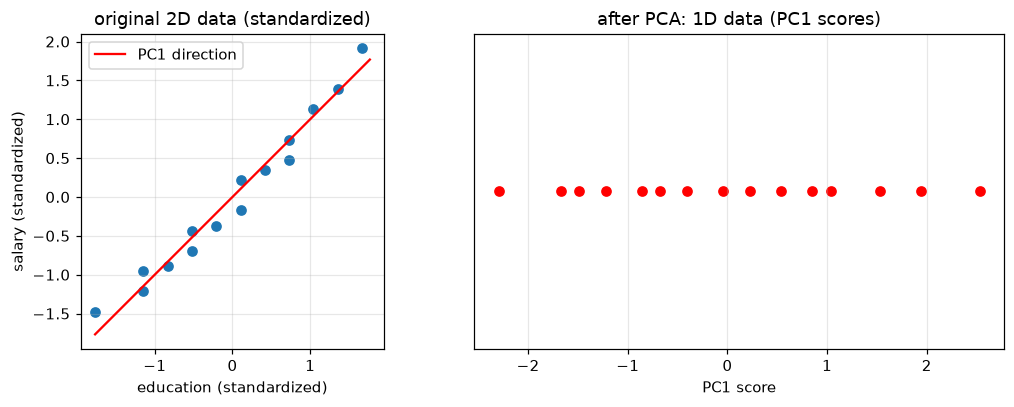

In [17]:
Z = standardize(X)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].scatter(Z[:, 0], Z[:, 1])
t = np.array([-2.5, 2.5])
ax[0].plot(t * eigvecs[0, 0], t * eigvecs[1, 0], "r-", label="PC1 direction")
ax[0].set(xlabel="education (standardized)", ylabel="salary (standardized)",
          title="original 2D data (standardized)")
ax[0].set_aspect("equal"); ax[0].legend()
ax[1].scatter(scores[:, 0], np.zeros(len(scores)), color="r")
ax[1].set(title="after PCA: 1D data (PC1 scores)", xlabel="PC1 score", yticks=[])
plt.tight_layout(); plt.show()

# result - for 2 standardized vars with correlation r, eigen values = 1 + r and 1 - r
# (eigen vectors [1,1]/sqrt(2) and [1,-1]/sqrt(2), sign can flip)
# here r = 0.985 -> eigen values 1.985 and 0.015 -> PC1 keeps 99.25% of the variance
# so 2 cols -> 1 PC1 score per employee and we lose very little info
# raw eigen vector pointed along salary only bc of units -> thats why we standardize

# Lab 5 - linear independence of real data from a csv

Q5 check the linear independence / dependence of real data by reading a csv or xls file

In [18]:
# Q5
# cols are independent if rank = no. of cols (compute_rank from lab 2)

# helper - dependent_columns
# why - rank only says IF theres a dependence, not WHICH col
# so add the cols 1 by 1 and watch the rank, if a col doesnt increase it
# -> that col is a combo of the cols before it
def dependent_columns(frame):
  M = frame.to_numpy(dtype=float)
  redundant, rank_so_far = [], 0
  for j, name in enumerate(frame.columns):
    r = compute_rank(M[:, :j + 1])
    if r == rank_so_far: # rank didnt grow -> col j adds nothing new
      redundant.append(name)
    rank_so_far = r
  return redundant

# helper - full check for a csv: read it, compare rank with no. of cols, print result
def check_csv_independence(path, drop=()):
  frame = pd.read_csv(path).drop(columns=list(drop))
  M = frame.to_numpy(dtype=float)
  r, k = compute_rank(M), M.shape[1]
  print(f"{path}: {frame.shape[0]} rows x {k} cols, rank = {r} ->",
        "cols linearly INDEPENDENT" if r == k else "cols linearly DEPENDENT")
  if r < k:
    print("   redundant col(s):", dependent_columns(frame))
  print("   inbuilt numpy rank agrees ?", r == np.linalg.matrix_rank(M))

In [19]:
# 1. iris csv from lab 1 (drop species, its a class label 0/1/2 not a measurement)
check_csv_independence("iris.csv", drop=["species"])

# 2. salary / education csv from lab 4
check_csv_independence("salary_education.csv")

# 3. iris + extra col sepal_len_mm = same measurement in mm
#    (same thing stored in 2 units is a common way real data gets dependent cols)
iris_mm = pd.read_csv("iris.csv")
iris_mm["sepal_len_mm"] = 10 * iris_mm["sepal_len"]
iris_mm.to_csv("iris_with_mm.csv", index=False)
check_csv_independence("iris_with_mm.csv", drop=["species"])

# result - iris (4 cols) and salary / education (2 cols) are independent
# (rank = no. of cols)
# with sepal_len_mm = 10 * sepal_len the rank stays 4 with 5 cols -> dependent,
# and the helper finds the redundant col
# (rows are always dependent here, 150 rows in R^4 -> max 4 independent rows)

iris.csv: 150 rows x 4 cols, rank = 4 -> cols linearly INDEPENDENT
   inbuilt numpy rank agrees ? True
salary_education.csv: 15 rows x 2 cols, rank = 2 -> cols linearly INDEPENDENT
   inbuilt numpy rank agrees ? True
iris_with_mm.csv: 150 rows x 5 cols, rank = 4 -> cols linearly DEPENDENT
   redundant col(s): ['sepal_len_mm']
   inbuilt numpy rank agrees ? True


# Lab 6 - normal random numbers, PMF and PDF, expectation and histogram of an img

Q6 (a) make random numbers that follow a normal distribution with mean 0 and variance 1

Q6 (b) find the probability mass function and density function of a 5x5 matrix

Q6 (c) find the expectation of vectors from a 32x32 img and the distribution of the pixels with a histogram

box muller (raw)     mean =  0.0009   variance = 0.9802
rng.standard_normal  mean =  0.0247   variance = 1.0069
normal_pdf same as inbuilt scipy.stats.norm.pdf ? True
first 8 numbers: [-0.3154 -0.2592  0.5793  1.5053 -0.1475  1.5015 -1.3423  1.7414]


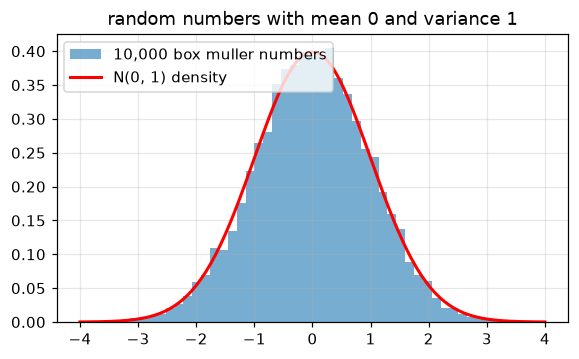

In [20]:
# Q6 (a)
# helper - box muller = raw way to make N(0,1) numbers from uniform random numbers
# math - if U1, U2 ~ U(0,1) then Z = sqrt(-2 ln U1) * cos(2 pi U2) is exactly N(0,1)
def box_muller(n):
  u1 = 1.0 - rng.random(n) # in (0, 1] so log(u1) never blows up
  u2 = rng.random(n)
  return np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)

# helper - normal pdf (the bell curve)
# math - f(x) = 1 / (sigma sqrt(2 pi)) * e^(-(x - mu)^2 / (2 sigma^2))
# why - drawn over the histograms in lab 6, 7, 8 to compare data vs theory
def normal_pdf(x, mu=0.0, sigma=1.0):
  return np.exp(-(x - mu) ** 2 / (2 * sigma ** 2)) / (sigma * np.sqrt(2 * np.pi))

z_raw = box_muller(10_000)
z_lib = rng.standard_normal(10_000) # inbuilt
for name, z in [("box muller (raw)", z_raw), ("rng.standard_normal", z_lib)]:
  print(f"{name:20s} mean = {z.mean():7.4f}   variance = {z.var(ddof=1):.4f}")
grid = np.linspace(-4, 4, 200)
same = np.allclose(normal_pdf(grid), stats.norm.pdf(grid))
print("normal_pdf same as inbuilt scipy.stats.norm.pdf ?", same)
print("first 8 numbers:", z_raw[:8])

plt.figure(figsize=(6, 3.4))
plt.hist(z_raw, bins=50, density=True, alpha=0.6, label="10,000 box muller numbers")
plt.plot(grid, normal_pdf(grid), "r", lw=2, label="N(0, 1) density")
plt.title("random numbers with mean 0 and variance 1"); plt.legend(loc="upper left")
plt.show()

# result - mean ~ 0, variance ~ 1 and the histogram follows the N(0,1) curve

5x5 matrix of dice throws:
 [[6 6 3 6 1]
 [2 5 6 1 5]
 [1 5 6 3 1]
 [2 4 5 4 3]
 [4 6 5 1 2]]


,x,count,PMF p(x),CDF F(x)
0,1,5,0.20,0.20
1,2,3,0.12,0.32
2,3,3,0.12,0.44
3,4,3,0.12,0.56
4,5,5,0.20,0.76
5,6,6,0.24,1.00


sum of PMF = 1.0 | fair dice theory: p(x) = 1/6 = 0.1667

5x5 matrix of N(0,1) numbers:
 [[-0.9223  0.6252 -1.1544 -0.9327 -1.4143]
 [ 0.9411 -0.8714  1.2675 -0.5313  0.128 ]
 [ 0.4114 -1.6169  0.2036  0.3499  1.14  ]
 [-0.9595 -0.817   0.6595  1.4124 -0.5925]
 [-1.2352 -0.3167 -1.0133  0.3978 -1.0798]]

PDF value f(x) at every entry:
 [[0.2607 0.3281 0.2049 0.2582 0.1467]
 [0.2562 0.2729 0.1787 0.3464 0.3957]
 [0.3666 0.108  0.3908 0.3753 0.2083]
 [0.2518 0.2857 0.321  0.1471 0.3347]
 [0.186  0.3794 0.2387 0.3686 0.2227]]
area under the PDF = 1.0


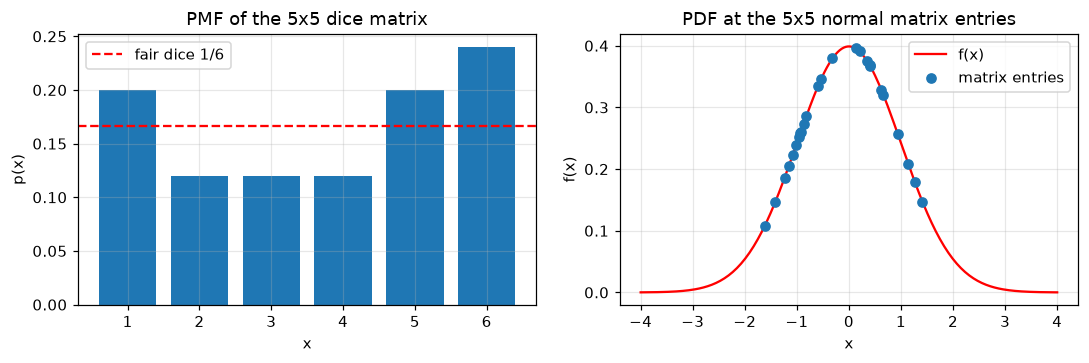

In [21]:
# Q6 (b)
# PMF is for discrete values, PDF is for continuous values -> make one 5x5 matrix of each
# discrete = 25 dice throws as 5x5, PMF p(x) = count of x / 25, CDF F(x) = P(X <= x)
# continuous = 5x5 of N(0,1) numbers, find f(x) at every entry
# note - f(x) is a density not a probability (P(X = x) = 0 for continuous),
# probability = area under f, so the total area has to be 1

# helper - empirical PMF, count each distinct value and divide by total -> adds up to 1
# why - used here and again for the img pixels in (c)
def empirical_pmf(values):
  vals, counts = np.unique(np.ravel(values), return_counts=True)
  return vals, counts / counts.sum()

dice = rng.integers(1, 7, size=(5, 5)) # discrete 5x5
print("5x5 matrix of dice throws:\n", dice)
vals, p = empirical_pmf(dice)
display(pd.DataFrame({"x": vals, "count": (p * dice.size).round().astype(int),
                      "PMF p(x)": p, "CDF F(x)": np.cumsum(p)}))
print("sum of PMF =", p.sum(), "| fair dice theory: p(x) = 1/6 =", round(1 / 6, 4))

cont = rng.standard_normal((5, 5)) # continuous 5x5
print("\n5x5 matrix of N(0,1) numbers:\n", cont)
print("\nPDF value f(x) at every entry:\n", normal_pdf(cont))
xs = np.linspace(-8, 8, 4001)
area = np.sum(normal_pdf(xs)) * (xs[1] - xs[0]) # sum of f(x) * dx
print("area under the PDF =", round(area, 6))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(vals, p, color="tab:blue")
ax[0].axhline(1 / 6, color="r", ls="--", label="fair dice 1/6")
ax[0].set(title="PMF of the 5x5 dice matrix", xlabel="x", ylabel="p(x)"); ax[0].legend()
ax[1].plot(grid, normal_pdf(grid), "r", label="f(x)")
ax[1].scatter(cont.ravel(), normal_pdf(cont.ravel()), zorder=3, label="matrix entries")
ax[1].set(title="PDF at the 5x5 normal matrix entries", xlabel="x", ylabel="f(x)")
ax[1].legend()
plt.tight_layout(); plt.show()

# result - PMF adds up to 1, with only 25 throws its near 1/6 but not = 1/6
# PDF values are highest near 0, area under the PDF = 1

E[X] = sum x p(x) = 144.7275 | mean of the 1024 pixels = 144.7275
Var[X] = E[X^2] - E[X]^2 = 5957.35 | sd = 77.18

expectation of each of the 32 col vectors:
 [144.  154.1 160.4 156.1 135.9 104.8  92.4  95.7  93.7  98.4  97.5 107.6
 108.3 115.7 127.  155.8 179.6 183.2 183.  184.1 182.8 176.6 178.7 180.3
 182.4 181.  179.8 173.1 149.2 122.8 119.5 127.9]


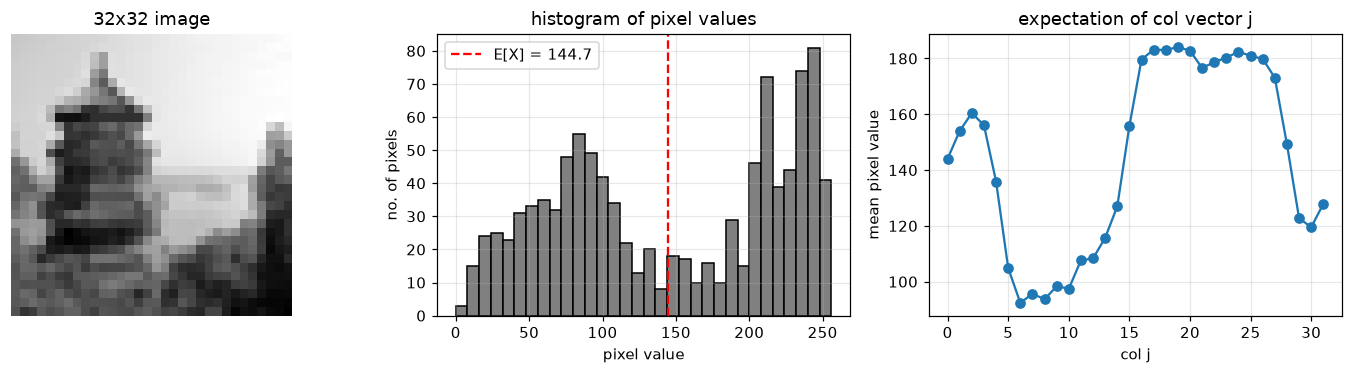

In [22]:
# Q6 (c)
# pixel value X (0..255) = a discrete random variable
# helper - expectation
# math - E[X] = sum of x * p(x) = dot product of values and probs
# why - with the pixel PMF it should = the plain avg of all pixels (good check on the PMF)
# same helper gives E[X^2] so Var[X] = E[X^2] - E[X]^2
def expectation(values, probs):
  return dot_product(values, probs)

pixels = img.flatten()
vals, p = empirical_pmf(pixels)
EX = expectation(vals, p)
VarX = expectation(vals ** 2, p) - EX ** 2
print(f"E[X] = sum x p(x) = {EX:.4f} | mean of the 1024 pixels = {pixels.mean():.4f}")
print(f"Var[X] = E[X^2] - E[X]^2 = {VarX:.2f} | sd = {np.sqrt(VarX):.2f}")

# expectation of vectors = each of the 32 col vectors (32x1) has its own expectation
col_expect = img.mean(axis=0)
print("\nexpectation of each of the 32 col vectors:\n", col_expect.round(1))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("32x32 image"); ax[0].axis("off")
ax[1].hist(pixels, bins=32, range=(0, 256), color="gray", edgecolor="black")
ax[1].axvline(EX, color="r", ls="--", label=f"E[X] = {EX:.1f}"); ax[1].legend()
ax[1].set(title="histogram of pixel values", xlabel="pixel value",
          ylabel="no. of pixels")
ax[2].plot(col_expect, "o-")
ax[2].set(title="expectation of col vector j", xlabel="col j",
          ylabel="mean pixel value")
plt.tight_layout(); plt.show()

# result - sum x p(x) = plain mean of the pixels
# for this photo the histogram is bimodal - dark pixels < ~130 (temple, trees) and
# bright pixels > ~190 (sky), E[X] ~ 145 is in the gap where there are few pixels
# so E[X] = balance point of the distribution, not a "typical" pixel
# col expectations show the same - temple cols low, sky cols high

# Lab 7 - normal observations, mean, sd, 68-95-99.7 rule, z-scores

Q7 generate random observations that follow a normal distribution and find the mean and sd

student tasks - (1) change mu from 170 to 165, (2) change sigma from 8 to 15, (3) generate 100, 1000 and 10000 observations, (4) compare the histogram with a bell curve, (5) % of observations within mu +- sigma, mu +- 2 sigma, mu +- 3 sigma, (6) z-scores

In [23]:
# Q7
from math import erf, sqrt

# helper - sample mean and sample sd (raw)
# math - mean = sum x / n,  sd = sqrt(sum (x - mean)^2 / (n - 1))
# why n - 1 (bessel's correction) - the mean comes from the same data which uses up
# 1 degree of freedom, dividing by n would give a sd thats too small on avg
def mean_std(x):
  n = len(x)
  m = sum(x) / n
  s = (sum((xi - m) ** 2 for xi in x) / (n - 1)) ** 0.5
  return m, s

# helper - % of observations within mu +- k sigma
# theory - P(|Z| <= k) = erf(k / sqrt(2)) = 68.27%, 95.45%, 99.73% for k = 1, 2, 3
def percent_within(x, mu, sigma, k):
  return 100 * np.mean(np.abs(x - mu) <= k * sigma)

# helper - z-scores, z = (x - mu) / sigma = how many sd's away from the mean
# puts any normal data on the N(0,1) scale
def z_scores(x, mu, sigma):
  return (x - mu) / sigma

In [24]:
rows, samples = [], {}
for mu, sigma in [(170, 8), (165, 15)]: # original, then the changed values (task 1, 2)
  for n in (100, 1_000, 10_000): # task 3
    x = rng.normal(mu, sigma, n)
    m, s = mean_std(x)
    samples[(mu, sigma, n)] = x
    rows.append({"mu": mu, "sigma": sigma, "n": n, "sample mean": m, "sample sd": s,
                 "% in mu+-1sd": percent_within(x, mu, sigma, 1), # task 5
                 "% in mu+-2sd": percent_within(x, mu, sigma, 2),
                 "% in mu+-3sd": percent_within(x, mu, sigma, 3)})
display(pd.DataFrame(rows).round(2))
print("theory (any normal distribution): %.2f %%, %.2f %%, %.2f %%"
      % tuple(100 * erf(k / sqrt(2)) for k in (1, 2, 3)))
x = samples[(165, 15, 10_000)]
same = np.allclose(mean_std(x), (x.mean(), x.std(ddof=1)))
print("mean_std same as inbuilt numpy ?", same)

,mu,sigma,n,sample mean,sample sd,% in mu+-1sd,% in mu+-2sd,% in mu+-3sd
0,170,8,100,169.26,7.86,71.00,95.00,100.00
1,170,8,1000,170.25,8.20,68.20,94.80,99.70
2,170,8,10000,169.91,8.04,67.59,95.36,99.75
3,165,15,100,165.90,15.40,70.00,96.00,99.00
4,165,15,1000,164.57,14.92,69.40,95.00,99.80
5,165,15,10000,164.76,14.92,69.34,95.27,99.63


theory (any normal distribution): 68.27 %, 95.45 %, 99.73 %
mean_std same as inbuilt numpy ? True


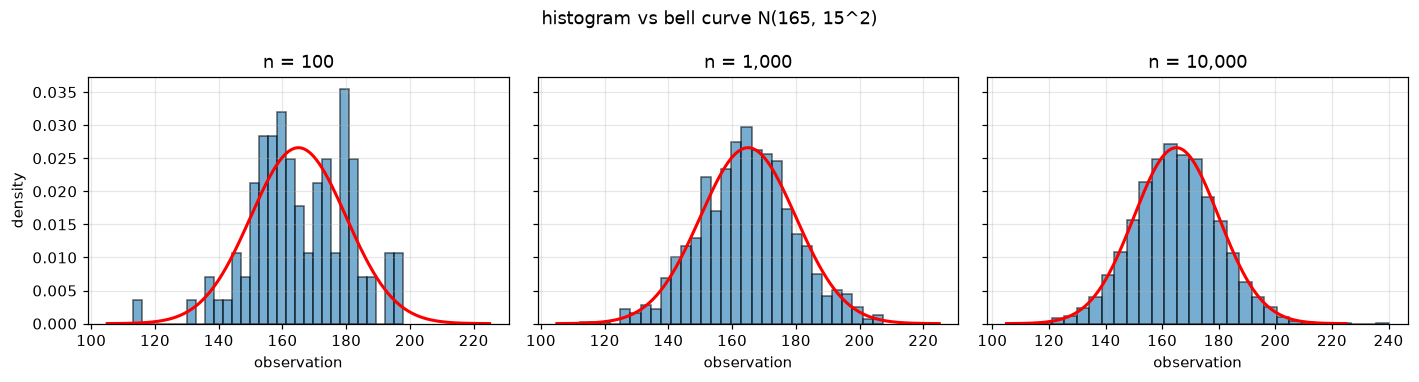

,observation x,z = (x - 165) / 15
0,164.503,-0.033
1,154.814,-0.679
2,135.022,-1.999
3,180.203,1.014
4,165.491,0.033
5,154.495,-0.700


all 1,000 z-scores: mean = -0.029, sd = 0.995  (N(0,1) has 0 and 1)
observations with |z| > 3 (unusual values): 2


In [25]:
# task 4 - histogram vs bell curve, mu = 165, sigma = 15
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
g = np.linspace(165 - 4 * 15, 165 + 4 * 15, 300)
for a, n in zip(ax, (100, 1_000, 10_000)):
  a.hist(samples[(165, 15, n)], bins=30, density=True, alpha=0.6, edgecolor="black")
  a.plot(g, normal_pdf(g, 165, 15), "r", lw=2)
  a.set(title=f"n = {n:,}", xlabel="observation")
ax[0].set_ylabel("density")
plt.suptitle("histogram vs bell curve N(165, 15^2)"); plt.tight_layout(); plt.show()

# task 6 - z-scores
x = samples[(165, 15, 1_000)]
z = z_scores(x, 165, 15)
display(pd.DataFrame({"observation x": x[:6], "z = (x - 165) / 15": z[:6]}).round(3))
zm, zs = mean_std(z)
print(f"all 1,000 z-scores: mean = {zm:.3f}, sd = {zs:.3f}  (N(0,1) has 0 and 1)")
print("observations with |z| > 3 (unusual values):", int(np.sum(np.abs(z) > 3)))

# result - mu 170 -> 165 shifts the curve left, sigma 8 -> 15 makes it wider and flatter
# more observations -> sample mean / sd closer to mu / sigma, histogram closer to curve
# (n = 100 is bumpy, n = 10000 is almost the curve)
# % within 1, 2, 3 sd are close to 68.27 / 95.45 / 99.73, n = 100 can be a few % off,
# n = 10000 is within ~1 %, some random variation always stays
# z-scores have mean ~ 0 and sd ~ 1, |z| > 3 is rare (~0.3% for normal data)

# Lab 8 - central limit theorem with student heights

Q8 real world example: student heights

(i) apply CLT to the data and verify SE = sigma / sqrt(n) experimentally

(ii) generate and plot a normal distribution

In [26]:
# Q8 (i)
# population = 10,000 student heights, half girls N(155, 6^2), half boys N(170, 7^2)
# the mixed population is NOT normal (2 humps) -> good test for CLT
# CLT - the mean of a sample is ~normal even if the population isnt, SE = sigma / sqrt(n)
heights = np.concatenate([rng.normal(155, 6, 5_000), # girls
                          rng.normal(170, 7, 5_000)]) # boys
mu_pop, sigma_pop = heights.mean(), heights.std() # population values so divide by N
print(f"population: N = {heights.size:,}, mean = {mu_pop:.2f} cm,",
      f"sigma = {sigma_pop:.2f} cm")

# helper - sample means
# why - CLT is about the distribution of the sample mean so we need lots of sample means
# takes `repeats` samples of size n and returns their means
# sd of these means = experimental SE -> compare with sigma / sqrt(n)
# sampling with replacement -> draws are independent so sigma / sqrt(n) holds exactly
def sample_means(population, n, repeats=2_000):
  idx = rng.integers(0, len(population), size=(repeats, n)) # random positions
  return population[idx].mean(axis=1)

rows, means_by_n = [], {}
for n in (2, 5, 10, 30, 50, 100):
  means = sample_means(heights, n)
  means_by_n[n] = means
  rows.append({"n": n, "mean of sample means": means.mean(),
               "SE experimental": means.std(ddof=1),
               "SE theory sigma/sqrt(n)": sigma_pop / np.sqrt(n)})
clt = pd.DataFrame(rows)
clt["difference %"] = 100 * (clt["SE experimental"] / clt["SE theory sigma/sqrt(n)"] - 1)
display(clt.round(3))

population: N = 10,000, mean = 162.45 cm, sigma = 9.97 cm


,n,mean of sample means,SE experimental,SE theory sigma/sqrt(n),difference %
0,2,162.500,7.045,7.050,-0.069
1,5,162.408,4.426,4.459,-0.748
2,10,162.459,3.164,3.153,0.345
3,30,162.499,1.845,1.820,1.356
4,50,162.443,1.417,1.410,0.462
5,100,162.454,0.981,0.997,-1.593


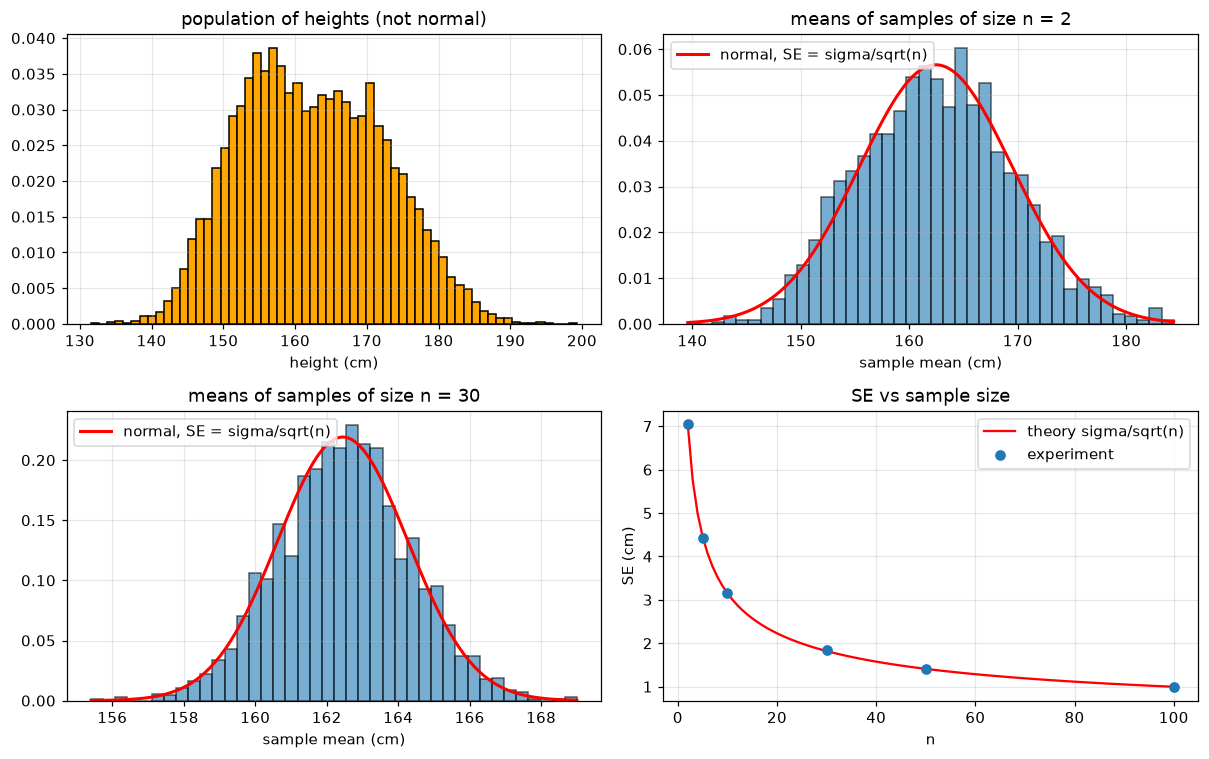

In [27]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
ax[0, 0].hist(heights, bins=60, density=True, color="orange", edgecolor="black")
ax[0, 0].set(title="population of heights (not normal)", xlabel="height (cm)")
for a, n in zip((ax[0, 1], ax[1, 0]), (2, 30)):
  a.hist(means_by_n[n], bins=40, density=True, alpha=0.6, edgecolor="black")
  g = np.linspace(means_by_n[n].min(), means_by_n[n].max(), 200)
  se = sigma_pop / np.sqrt(n)
  a.plot(g, normal_pdf(g, mu_pop, se), "r", lw=2, label="normal, SE = sigma/sqrt(n)")
  a.set(title=f"means of samples of size n = {n}", xlabel="sample mean (cm)")
  a.legend(loc="upper left")
nn = np.arange(2, 101)
ax[1, 1].plot(nn, sigma_pop / np.sqrt(nn), "r", label="theory sigma/sqrt(n)")
ax[1, 1].scatter(clt["n"], clt["SE experimental"], zorder=3, label="experiment")
ax[1, 1].set(title="SE vs sample size", xlabel="n", ylabel="SE (cm)")
ax[1, 1].legend()
plt.tight_layout(); plt.show()

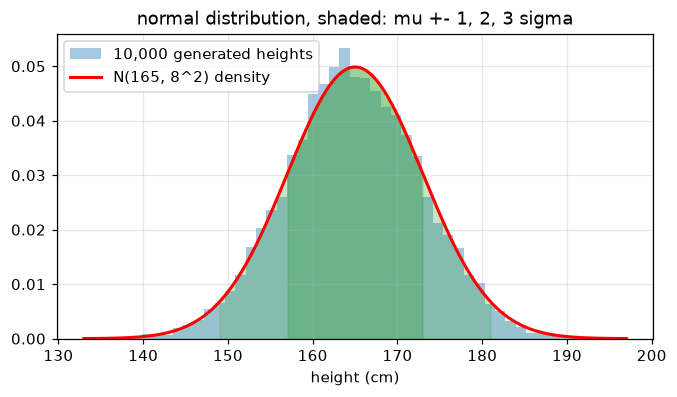

In [28]:
# Q8 (ii) generate and plot a normal distribution, heights ~ N(165, 8^2)
mu, sigma = 165, 8
sample = rng.normal(mu, sigma, 10_000)
g = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 400)
plt.figure(figsize=(7, 3.6))
plt.hist(sample, bins=50, density=True, alpha=0.4, label="10,000 generated heights")
plt.plot(g, normal_pdf(g, mu, sigma), "r", lw=2, label="N(165, 8^2) density")
for k, shade in zip((3, 2, 1), (0.10, 0.18, 0.28)): # shade mu +- 3, 2, 1 sigma
  band = np.abs(g - mu) <= k * sigma
  plt.fill_between(g[band], normal_pdf(g[band], mu, sigma),
                   color="tab:green", alpha=shade)
plt.title("normal distribution, shaded: mu +- 1, 2, 3 sigma"); plt.xlabel("height (cm)")
plt.legend(loc="upper left")
plt.show()

# result - (i) experimental SE matches sigma / sqrt(n) within a few % for every n
# -> verified
# SE falls like 1 / sqrt(n), n 10 -> 100 divides the SE by ~ sqrt(10) = 3.2
# population has 2 humps but the sample means are already bell shaped at n = 30 -> CLT
# mean of the sample means = mu
# (ii) generated heights follow the N(165, 8^2) curve, shaded = mu +- 1, 2, 3 sigma

# Lab 9 - chi square goodness of fit, t-test, F-test

Q9 (a) make a chi square distribution from squared normal variables and apply a goodness of fit test

Q9 (b) think of 2 teaching methods and compare the avg EST marks with a t-test

Q9 (c) compare the variance of marks of the CSBS and AI/ML classes with an F-test

sample mean     = 2.984  (theory k  = 3)
sample variance = 5.948  (theory 2k = 6)
observed counts: [ 980 1022  966 1056 1050  962 1022  976  998  968]
expected counts: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]
chi-square = 11.208, df = 9, critical = 16.919, p-value = 0.2617
decision: do not reject H0 -> the data fit chi-square(3)
inbuilt scipy chisquare: stat = 11.208, p-value = 0.2617


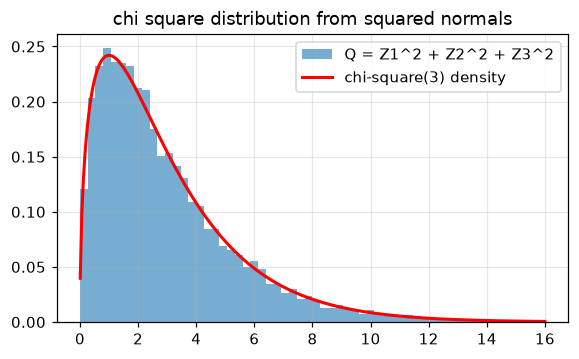

In [29]:
# Q9
# all 3 tests have the same steps - write H0 and H1, find the test statistic from data,
# reject H0 if its in the critical region (same as p-value < alpha = 0.05)
# helpers find the statistic from the formula, scipy only gives the distribution values
# (ppf = table value, sf / cdf = tail area) -> replaces the stats tables

# Q9 (a)
# if Z1..Zk are independent N(0,1) then Q = Z1^2 + ... + Zk^2 ~ chi square with k df
# (mean k, variance 2k), make 10,000 Qs with k = 3
# H0 - data comes from chi square(3), H1 - it doesnt

# helper - chi square goodness of fit
# math - chi^2 = sum (O - E)^2 / E,  df = bins - 1 (no parameter estimated from data)
# bins - 10 bins of equal probability under chi square(3) (10%, 20% ... quantiles)
# so expected count = 10000 / 10 = 1000 per bin, way above the min of 5
def chi_square_gof(observed, expected, alpha=0.05):
  O, E = np.asarray(observed, float), np.asarray(expected, float)
  stat = np.sum((O - E) ** 2 / E)
  df = len(O) - 1
  return stat, df, stats.chi2.ppf(1 - alpha, df), stats.chi2.sf(stat, df)

k, N = 3, 10_000
Q = (rng.standard_normal((N, k)) ** 2).sum(axis=1) # sum of k squared normals
m, s = mean_std(Q)
print(f"sample mean     = {m:.3f}  (theory k  = {k})")
print(f"sample variance = {s**2:.3f}  (theory 2k = {2 * k})")

edges = stats.chi2.ppf(np.linspace(0, 1, 11), k) # 10 equal prob bins, last edge = inf
observed, _ = np.histogram(Q, bins=edges)
expected = np.full(10, N / 10)
stat, df, crit, p = chi_square_gof(observed, expected)
print("observed counts:", observed)
print("expected counts:", expected.astype(int))
print(f"chi-square = {stat:.3f}, df = {df}, critical = {crit:.3f}, p-value = {p:.4f}")
print("decision:", "reject H0" if stat > crit
      else "do not reject H0 -> the data fit chi-square(3)")
res = stats.chisquare(observed, expected) # inbuilt check
print(f"inbuilt scipy chisquare: stat = {res.statistic:.3f}, p-value = {res.pvalue:.4f}")

g = np.linspace(0.01, 16, 300)
plt.figure(figsize=(6, 3.4))
plt.hist(Q, bins=60, range=(0, 16), density=True, alpha=0.6,
         label="Q = Z1^2 + Z2^2 + Z3^2")
plt.plot(g, stats.chi2.pdf(g, k), "r", lw=2, label="chi-square(3) density")
plt.title("chi square distribution from squared normals"); plt.legend(); plt.show()

# result - mean ~ 3, variance ~ 6, test does NOT reject H0 -> data fits chi square(3)

In [30]:
# Q9 (b)
# section A = method 1 (only lectures)
# section B = method 2 (lectures + weekly problem solving labs)
# EST marks (out of 100) of 12 students each
# H0 - mu1 = mu2 (no difference),  H1 - mu1 != mu2 (two tailed),  alpha = 0.05

# helper - pooled two sample t-test
# math - t = (mean1 - mean2) / (sp * sqrt(1/n1 + 1/n2)),  df = n1 + n2 - 2
#        sp^2 = ((n1 - 1) s1^2 + (n2 - 1) s2^2) / (n1 + n2 - 2)
# pooled variance assumes both sections have the same spread (F-test in (c) checks this)
# reuses mean_std from lab 7
def t_test_pooled(a, b, alpha=0.05):
  (m1, s1), (m2, s2) = mean_std(a), mean_std(b)
  n1, n2 = len(a), len(b)
  sp2 = ((n1 - 1) * s1 ** 2 + (n2 - 1) * s2 ** 2) / (n1 + n2 - 2)
  t = (m1 - m2) / np.sqrt(sp2 * (1 / n1 + 1 / n2))
  df = n1 + n2 - 2
  return t, df, stats.t.ppf(1 - alpha / 2, df), 2 * stats.t.sf(abs(t), df)

method1 = np.array([62, 58, 71, 65, 55, 68, 60, 73, 66, 59, 64, 70]) # only lectures
method2 = np.array([70, 75, 68, 80, 72, 77, 65, 82, 74, 71, 78, 69]) # lectures + labs
for name, marks_ in [("method 1", method1), ("method 2", method2)]:
  m, s = mean_std(marks_)
  print(f"{name}: mean = {m:.2f}, sd = {s:.2f}, n = {len(marks_)}")

t, df, crit, p = t_test_pooled(method1, method2)
print(f"\nt = {t:.3f}, df = {df}, critical value = +-{crit:.3f}, p-value = {p:.5f}")
print("decision:", "reject H0 -> the 2 methods give different avg marks"
      if abs(t) > crit else "do not reject H0 -> no significant difference")
res = stats.ttest_ind(method1, method2, equal_var=True) # inbuilt check
print(f"inbuilt scipy ttest_ind: t = {res.statistic:.3f}, p-value = {res.pvalue:.5f}")

# result - |t| > critical value and p < 0.05 -> reject H0
# method 2 gives significantly higher avg EST marks

method 1: mean = 64.25, sd = 5.63, n = 12
method 2: mean = 73.42, sd = 5.16, n = 12

t = -4.159, df = 22, critical value = +-2.074, p-value = 0.00041
decision: reject H0 -> the 2 methods give different avg marks
inbuilt scipy ttest_ind: t = -4.159, p-value = 0.00041


variance CSBS = 9.17, variance AI/ML = 105.39

CSBS vs AI/ML:
   F = 0.087, df = (9, 9), accept [0.248, 4.026], p-value = 0.0012
   decision: reject H0 -> variances differ

assumption check for (b): method 1 vs method 2:
   F = 1.189, df = (11, 11), accept [0.288, 3.474], p-value = 0.7792
   decision: do not reject H0 -> equal variances


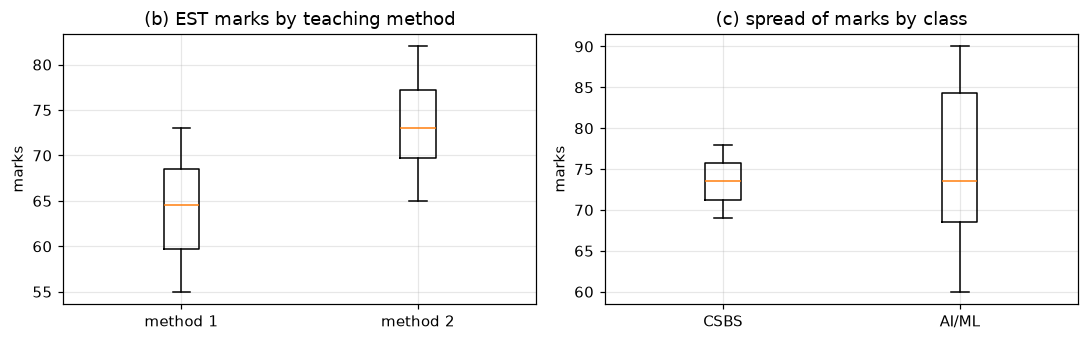

In [31]:
# Q9 (c)
# H0 - var1 = var2,  H1 - var1 != var2,  alpha = 0.05

# helper - F-test
# math - F = s1^2 / s2^2 with (n1 - 1, n2 - 1) df, if variances are equal F ~ 1
# two tailed p-value = 2 * min(P(F <= f), P(F >= f))
# reject H0 if F is below the lower or above the upper 2.5% critical value
# scipy has no ready made 2 sample F-test so this helper is the way to do it
# also used a 2nd time to check the equal variance assumption of (b)
def f_test(a, b, alpha=0.05):
  (_, s1), (_, s2) = mean_std(a), mean_std(b)
  F = s1 ** 2 / s2 ** 2
  d1, d2 = len(a) - 1, len(b) - 1
  crit = (stats.f.ppf(alpha / 2, d1, d2), stats.f.ppf(1 - alpha / 2, d1, d2))
  p = 2 * min(stats.f.cdf(F, d1, d2), stats.f.sf(F, d1, d2))
  return F, (d1, d2), crit, p

csbs = np.array([72, 75, 70, 78, 74, 69, 77, 73, 71, 76])
aiml = np.array([65, 85, 70, 90, 60, 82, 75, 68, 88, 72])
var_csbs, var_aiml = mean_std(csbs)[1] ** 2, mean_std(aiml)[1] ** 2
print(f"variance CSBS = {var_csbs:.2f}, variance AI/ML = {var_aiml:.2f}")

tests = [("CSBS vs AI/ML", csbs, aiml),
         ("assumption check for (b): method 1 vs method 2", method1, method2)]
for label, a, b in tests:
  F, dfs, (lo, hi), p = f_test(a, b)
  print(f"\n{label}:")
  print(f"   F = {F:.3f}, df = {dfs}, accept [{lo:.3f}, {hi:.3f}], p-value = {p:.4f}")
  print("   decision:", "reject H0 -> variances differ" if p < 0.05
        else "do not reject H0 -> equal variances")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].boxplot([method1, method2]); ax[0].set_xticks([1, 2], ["method 1", "method 2"])
ax[0].set(title="(b) EST marks by teaching method", ylabel="marks")
ax[1].boxplot([csbs, aiml]); ax[1].set_xticks([1, 2], ["CSBS", "AI/ML"])
ax[1].set(title="(c) spread of marks by class", ylabel="marks")
plt.tight_layout(); plt.show()

# result - F is outside the accept region -> variances differ, AI/ML marks are way more
# spread out than CSBS
# method 1 vs 2 - F-test does not reject equal variances -> pooled t-test in (b) is ok
# chi square and t-test helpers give the same numbers as the inbuilt scipy fns

# Lab 10 - type I and type II errors in binary classification

| real situation | test says: healthy | test says: disease |
|---|---|---|
| actually healthy | correct (TN) | type I error (FP) |
| actually diseased | type II error (FN) | correct (TP) |

Q10 part 1 - medical screening test on 1000 people: (a) 100 actually have the disease, (b) 900 are healthy but test says diseased, (c) test wrongly says 5% of healthy people are diseased, (d) test misses 10% of diseased people

Q10 part 2 - simulate airport security for 10000 passengers, H0: passenger does NOT have a prohibited item, H1: passenger HAS a prohibited item. find (i) no. of type 1 and 2 errors, (ii) connect it with the confusion matrix

In [32]:
# Q10
# H0 = "healthy / nothing wrong"
# type I error = reject a true H0 (false alarm), prob = alpha
# type II error = keep a false H0 (a miss), prob = beta, 1 - beta = power (= sensitivity)

# helper - confusion counts, TP / FP / FN / TN from 2 true/false arrays (True = positive)
# these 4 counts = the 2x2 confusion matrix above
def confusion_counts(actual, predicted):
  actual, predicted = np.asarray(actual, bool), np.asarray(predicted, bool)
  TP = int(np.sum(actual & predicted))
  FP = int(np.sum(~actual & predicted)) # type I error
  FN = int(np.sum(actual & ~predicted)) # type II error
  TN = int(np.sum(~actual & ~predicted))
  return TP, FP, FN, TN

# helper - error report, shows the confusion matrix and turns the 4 counts into rates
# alpha = FP / (FP + TN), beta = FN / (FN + TP), accuracy, sensitivity, specificity,
# precision. both parts of the lab use it
def error_report(TP, FP, FN, TN, neg="Healthy", pos="Disease"):
  display(pd.DataFrame([[TN, FP], [FN, TP]],
                       index=[f"Actual: {neg}", f"Actual: {pos}"],
                       columns=[f"Test says: {neg}", f"Test says: {pos}"]))
  r = {"alpha (Type I rate)": FP / (FP + TN),
       "beta (Type II rate)": FN / (FN + TP),
       "accuracy": (TP + TN) / (TP + FP + FN + TN),
       "sensitivity = power": TP / (TP + FN),
       "specificity": TN / (TN + FP),
       "precision": TP / (TP + FP)}
  print(f"Type I errors (FP) = {FP},  Type II errors (FN) = {FN}")
  for name, value in r.items():
    print(f"   {name:22s} = {value:.4f}")
  return r

In [33]:
# part 1 - medical screening
# 100 have the disease so 900 are healthy
# (b) "900 are healthy but test says diseased" cant be literal bc (c) says only 5% of
# the healthy are wrongly flagged -> reading (b) as "900 are healthy"
healthy, diseased = 900, 100
FP = round(0.05 * healthy); TN = healthy - FP # (c) 5% of healthy flagged -> type I
FN = round(0.10 * diseased); TP = diseased - FN # (d) 10% of diseased missed -> type II
med = error_report(TP, FP, FN, TN)

# result - 94.5% accurate but precision only 66.7% -> of 135 +ve tests, 45 are healthy
# healthy outnumber diseased 9 to 1 so even 5% false alarms = lots of FPs
# (base rate effect)
# type II (missed patient) is worse in screening -> a +ve result gets a 2nd confirm test

,Test says: Healthy,Test says: Disease
Actual: Healthy,855,45
Actual: Disease,10,90


Type I errors (FP) = 45,  Type II errors (FN) = 10
   alpha (Type I rate)    = 0.0500
   beta (Type II rate)    = 0.1000
   accuracy               = 0.9450
   sensitivity = power    = 0.9000
   specificity            = 0.9500
   precision              = 0.6667


In [34]:
# part 2 - airport security, my model of the problem
# 2% of passengers carry a prohibited item
# scanner gives each bag a threat score - clean bag ~ N(0,1), bag with an item ~ N(3,1)
# rule = hypothesis test -> alarm (reject H0) if score > 1.645
# 1.645 = 95% point of N(0,1) -> planned alpha = 5%
# planned beta = P(N(3,1) <= 1.645) = phi(1.645 - 3) ~ 8.8%
# confusion matrix - TN = clean + no alarm
#                    FP = clean but alarm (type I, innocent person searched)
#                    FN = item but no alarm (type II, threat missed)
#                    TP = item + alarm
N, prevalence, shift, threshold = 10_000, 0.02, 3.0, 1.645
has_item = rng.random(N) < prevalence # truth, True = H1 is true
score = rng.standard_normal(N) + shift * has_item # N(0,1) if clean, N(3,1) if item
alarm = score > threshold # decision, True = reject H0

TP, FP, FN, TN = confusion_counts(has_item, alarm)
print(f"passengers with an item: {has_item.sum()}, clean: {(~has_item).sum()}")
air = error_report(TP, FP, FN, TN, neg="No item", pos="Item")
print(f"\nplanned rates: alpha = {stats.norm.sf(threshold):.4f}, "
      f"beta = {stats.norm.cdf(threshold - shift):.4f}")

from sklearn.metrics import confusion_matrix # inbuilt check
print("inbuilt sklearn confusion_matrix [[TN, FP], [FN, TP]] agrees ?",
      np.array_equal(confusion_matrix(has_item, alarm), [[TN, FP], [FN, TP]]))

passengers with an item: 190, clean: 9810


,Test says: No item,Test says: Item
Actual: No item,9352,458
Actual: Item,13,177


Type I errors (FP) = 458,  Type II errors (FN) = 13
   alpha (Type I rate)    = 0.0467
   beta (Type II rate)    = 0.0684
   accuracy               = 0.9529
   sensitivity = power    = 0.9316
   specificity            = 0.9533
   precision              = 0.2787

planned rates: alpha = 0.0500, beta = 0.0877


inbuilt sklearn confusion_matrix [[TN, FP], [FN, TP]] agrees ? True


In [35]:
# how the threshold trades type I vs type II errors (same passengers)
rows = []
for t in (1.0, 1.645, 2.326):
  tp, fp, fn, tn = confusion_counts(has_item, score > t)
  rows.append({"threshold": t, "Type I errors (FP)": fp, "Type II errors (FN)": fn,
               "alpha": fp / (fp + tn), "beta": fn / (fn + tp)})
display(pd.DataFrame(rows).round(4))

# result
# (i) type I = FP (false alarms), type II = FN (missed items), counts are in the matrix
#     empirical alpha ~ planned 5%, beta is near 8.8% but varies more (only ~200 carriers)
#     precision is low (most alarms are false) bc clean passengers outnumber
#     carriers ~49 to 1
# (ii) rows = truth (H0 / H1 true), cols = decision (keep / reject H0)
#      diagonal = correct, FP = type I, FN = type II
# lower threshold -> fewer misses (type II) but more innocent people searched (type I),
# higher threshold = the opposite, cant lower both with the same scanner
# at an airport a missed weapon is way worse than a manual search -> keep the threshold
# low (accept a higher alpha to keep beta small)
# only a better scanner (score distributions further apart) lowers both

,threshold,Type I errors (FP),Type II errors (FN),alpha,beta
0,1.000,1535,2,0.1565,0.0105
1,1.645,458,13,0.0467,0.0684
2,2.326,85,50,0.0087,0.2632
